In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)

n = 1000

dates = pd.to_datetime(
    np.random.choice(
        pd.date_range("2025-01-01", "2025-12-31"),
        n
    )
)

categories = np.random.choice(
    ["Electronics", "Fashion", "Beauty", "Home & Kitchen"],
    n
)

regions = np.random.choice(
    ["North", "South", "East", "West"],
    n
)

products = {
    "Electronics": ["Headphones", "Keyboard", "Smart Watch", "Speaker"],
    "Fashion": ["T-Shirt", "Bag", "Sneakers", "Scarf"],
    "Beauty": ["Face Wash", "Moisturizer", "Shampoo", "Sunscreen"],
    "Home & Kitchen": ["Bottle", "Storage Box", "Lamp", "Cookware"]
}

prices = {
    "Electronics": (2500, 25000),
    "Fashion": (800, 9000),
    "Beauty": (400, 4500),
    "Home & Kitchen": (500, 7000)
}

product_names = []
unit_prices = []

for category in categories:
    product_names.append(
        np.random.choice(products[category])
    )

    low, high = prices[category]

    unit_prices.append(
        np.random.randint(low, high + 1)
    )

sales = pd.DataFrame({
    "Order_ID": [f"ORD{i:05d}" for i in range(1, n + 1)],
    "Order_Date": dates,
    "Region": regions,
    "Category": categories,
    "Product": product_names,
    "Units_Sold": np.random.randint(1, 8, n),
    "Unit_Price": unit_prices
})

sales.head()

,Order_ID,Order_Date,Region,Category,Product,Units_Sold,Unit_Price
0,ORD00001,2025-04-13,North,Beauty,Sunscreen,6,4079
1,ORD00002,2025-12-15,West,Beauty,Sunscreen,5,4124
2,ORD00003,2025-09-28,East,Electronics,Smart Watch,4,3345
3,ORD00004,2025-04-17,North,Fashion,Scarf,5,6577
4,ORD00005,2025-03-13,East,Fashion,T-Shirt,2,6747


In [3]:
sales["Revenue"] = (
    sales["Units_Sold"] * sales["Unit_Price"]
)

sales["Cost"] = (
    sales["Revenue"] *
    np.random.uniform(0.55, 0.82, len(sales))
).round(2)

sales["Profit"] = (
    sales["Revenue"] - sales["Cost"]
).round(2)

sales["Month"] = sales["Order_Date"].dt.month

sales.head()

,Order_ID,Order_Date,Region,Category,Product,Units_Sold,Unit_Price,Revenue,Cost,Profit,Month
0,ORD00001,2025-04-13,North,Beauty,Sunscreen,6,4079,24474,18652.21,5821.79,4
1,ORD00002,2025-12-15,West,Beauty,Sunscreen,5,4124,20620,12748.43,7871.57,12
2,ORD00003,2025-09-28,East,Electronics,Smart Watch,4,3345,13380,10750.85,2629.15,9
3,ORD00004,2025-04-17,North,Fashion,Scarf,5,6577,32885,26024.40,6860.60,4
4,ORD00005,2025-03-13,East,Fashion,T-Shirt,2,6747,13494,8651.27,4842.73,3


In [4]:
print("Dataset Shape:", sales.shape)

print("\nMissing Values:")
print(sales.isnull().sum())

print("\nColumn Names:")
print(sales.columns.tolist())

Dataset Shape: (1000, 11)

Missing Values:
Order_ID      0
Order_Date    0
Region        0
Category      0
Product       0
Units_Sold    0
Unit_Price    0
Revenue       0
Cost          0
Profit        0
Month         0
dtype: int64

Column Names:
['Order_ID', 'Order_Date', 'Region', 'Category', 'Product', 'Units_Sold', 'Unit_Price', 'Revenue', 'Cost', 'Profit', 'Month']


In [5]:
total_revenue = sales["Revenue"].sum()
total_profit = sales["Profit"].sum()
total_orders = sales["Order_ID"].nunique()
total_units = sales["Units_Sold"].sum()

profit_margin = (
    total_profit / total_revenue
) * 100

print(f"Total Revenue: PKR {total_revenue:,.0f}")
print(f"Total Profit: PKR {total_profit:,.0f}")
print(f"Total Orders: {total_orders}")
print(f"Total Units Sold: {total_units}")
print(f"Profit Margin: {profit_margin:.2f}%")

Total Revenue: PKR 25,856,841
Total Profit: PKR 8,236,220
Total Orders: 1000
Total Units Sold: 4042
Profit Margin: 31.85%


In [6]:
category_summary = sales.groupby("Category")[
    ["Revenue", "Profit"]
].sum().sort_values(
    by="Revenue", ascending=False
)

print(category_summary.round(2))

                 Revenue      Profit
Category                            
Electronics     14779249  4709121.36
Fashion          4909344  1505364.25
Home & Kitchen   3616895  1191754.80
Beauty           2551353   829979.84


In [7]:
monthly_summary = sales.groupby(
    sales["Order_Date"].dt.to_period("M")
)[["Revenue", "Profit"]].sum()

monthly_summary.index = monthly_summary.index.astype(str)

print(monthly_summary.round(2))

            Revenue     Profit
Order_Date                    
2025-01     1641880  560822.44
2025-02     1893272  595393.41
2025-03     1721705  515309.02
2025-04     2530989  806828.15
2025-05     2515247  748598.23
2025-06     1707187  549182.51
2025-07     2385815  780445.75
2025-08     2293333  764784.75
2025-09     2209498  702744.44
2025-10     2464522  806985.62
2025-11     2382681  759927.37
2025-12     2110712  645198.56


In [8]:
region_summary = sales.groupby("Region")[
    ["Revenue", "Profit"]
].sum().sort_values(
    by="Revenue", ascending=False
)

print(region_summary.round(2))

        Revenue      Profit
Region                     
South   7393528  2333639.27
North   6568783  2137857.75
West    6212185  1976876.88
East    5682345  1787846.35


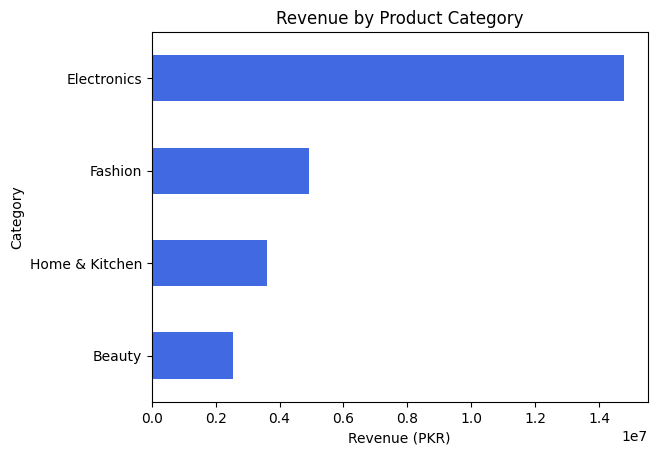

In [10]:
category_summary["Revenue"].sort_values().plot(
    kind="barh",
    color="royalblue")
plt.title("Revenue by Product Category")
plt.xlabel("Revenue (PKR)")
plt.ylabel("Category")
plt.show()

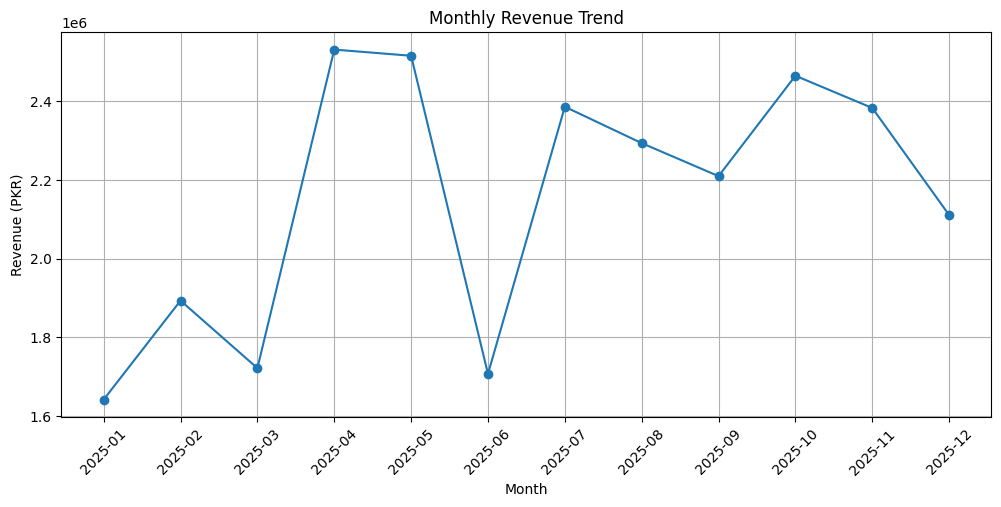

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_summary.index,
    monthly_summary["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (PKR)")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

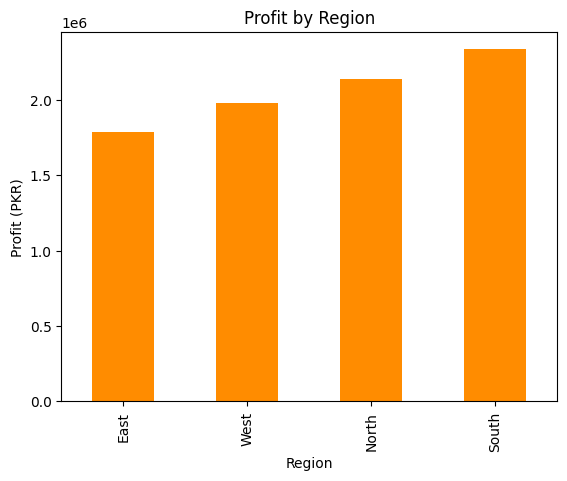

In [12]:
region_summary["Profit"].sort_values().plot(
    kind="bar",
    color="darkorange"
)

plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Profit (PKR)")
plt.show()

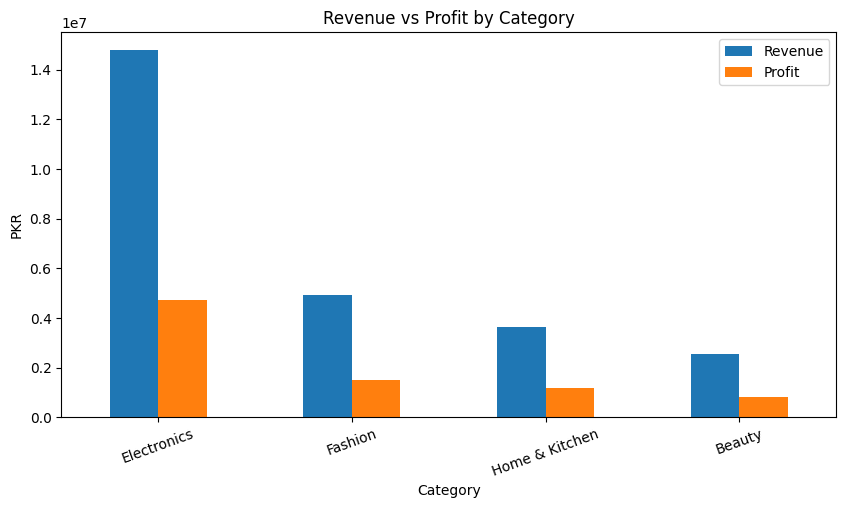

In [13]:
category_summary[["Revenue", "Profit"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Revenue vs Profit by Category")
plt.xlabel("Category")
plt.ylabel("PKR")
plt.xticks(rotation=20)
plt.show()

In [14]:
best_category = category_summary["Revenue"].idxmax()
best_region = region_summary["Profit"].idxmax()
best_month = monthly_summary["Revenue"].idxmax()

print("Highest Revenue Category:", best_category)
print("Most Profitable Region:", best_region)
print("Best Revenue Month:", best_month)

Highest Revenue Category: Electronics
Most Profitable Region: South
Best Revenue Month: 2025-04


In [15]:
sales.to_csv("retail_sales_data.csv", index=False)

category_summary.to_csv("category_summary.csv")
monthly_summary.to_csv("monthly_summary.csv")
region_summary.to_csv("region_summary.csv")

print("All CSV files saved successfully!")

All CSV files saved successfully!
